Kütüphanelerin Tanımlanması

In [6]:

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize


Veri Setinin İncelenmesi

In [ ]:
spam = pd.read_csv("data/spam.csv")
spam.head()

,crl.tot,dollar,bang,money,n000,make,yesno
0,278,0.000,0.778,0.00,0.00,0.00,y
1,1028,0.180,0.372,0.43,0.43,0.21,y
2,2259,0.184,0.276,0.06,1.16,0.06,y
3,191,0.000,0.137,0.00,0.00,0.00,y
4,191,0.000,0.135,0.00,0.00,0.00,y


Kategorik Değişkenlerin Belirlenmesi

In [21]:
categorical_columns = spam.select_dtypes(include = ['object', 'category']).columns.tolist()
label_encoders = {col: LabelEncoder() for col in categorical_columns}
for col in categorical_columns:
    spam[col] = label_encoders[col].fit_transform(spam[col])

Özellik/Hedef ve Train/Test Ayrımı

In [14]:
X = spam.drop('yesno', axis = 1)
y = spam['yesno']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

Ölçekleme ve PCA

In [15]:
pca = PCA(n_components = 2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print("Explained variance ratio:", pca.explained_variance_ratio_)

Explained variance ratio: [9.99996219e-01 2.28286897e-06]


Modelin Eğitimi

In [16]:
dtree = DecisionTreeClassifier(random_state = 42)
dtree.fit(X_train_pca, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

DecisionPlot Fonksiyonu

In [17]:
def decisionplot(model, X, y, resolution=200, ax=None):

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    cols = X.columns
    x_min, x_max = X.iloc[:, 0].min() -1, X.iloc[:, 0].max() + 1
    y_min, y_max = X.iloc[:, 1].min() -1, X.iloc[:, 1].max() + 1

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolution),
                         np.linspace(y_min, y_max, resolution))
    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=cols)
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy ,Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X.iloc[:, 0], X.iloc[:,1], c=y, cmap="coolwarm", edgecolors="k", s=15)
    ax.set_xlabel(cols[0])
    ax.set_ylabel(cols[1])
    ax.set_title("Karar Ağacı")
    return ax

Karar Sınırının Grafiğini Oluşturma

c:\Users\Berkay\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


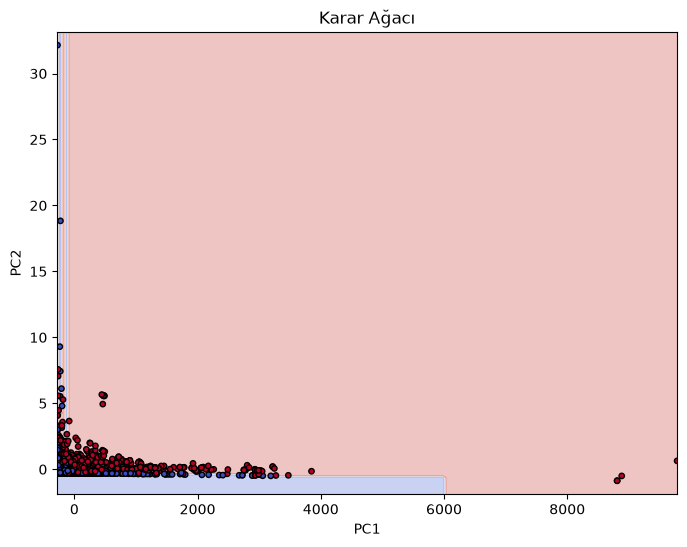

In [24]:
decisionplot(dtree, pd.DataFrame(X_train_pca, columns = ['PC1', 'PC2']), y_train)
plt.show()

Metrik Değerlerinin Çıktısını Yazdırma

In [19]:
predictions = dtree.predict(X_test_pca)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, average = 'weighted')
recall = recall_score(y_test, predictions, average = 'weighted')
f1 = f1_score(y_test, predictions, average = 'weighted')

print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

Accuracy: 0.81
Precision: 0.81
Recall: 0.81
F1 Score: 0.81


AUC-ROC Hesaplamasını Grafiğe Aktarma

AUC: 0.769


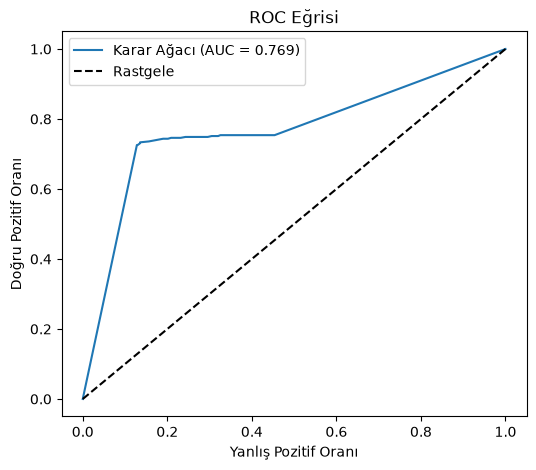

In [20]:
y_proba = dtree.predict_proba(X_test_pca)[:, 1]
auc_score = roc_auc_score(y_test, y_proba)
print(f"AUC: {auc_score:.3f}")

fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Karar Ağacı (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Rastgele")
plt.xlabel("Yanlış Pozitif Oranı")
plt.ylabel("Doğru Pozitif Oranı")
plt.title("ROC Eğrisi")
plt.legend()
plt.show()

Bulguların Değerlendirilmesi

Modelin test setindeki accuracy, weighted precision, weighted recall ve weighted F1 değerleri yaklaşık 0.81’dir. Bu sonuç, modelin test verisindeki sınıflandırmalarının oldukça uygun olduğunu gösteriyor. Bununla birlikte, veri setinde spam olmayan e-postalar daha fazla olduğu ve metrikler weighted ortalamayla hesaplandığı için bu değerler spam sınıfındaki performansı tek başına açıklamaz. Spam tespitinin başarısını daha iyi değerlendirmek için spam sınıfına ait precision, recall ve F1 değerleri de incelenmelidir. Örneğin, spam e-postaları kaçırmak önemliyse recall; normal e-postaların yanlışlıkla spam olarak işaretlenmesi daha maliyetliyse precision öne çıkar.

AUC-ROC değerinin yaklaşık 0.77 olması, modelin spam ve spam olmayan e-postaları ayırt etme becerisinin rastgele tahminden daha iyi, fakat kusursuz olmadığını gösterir. AUC farklı karar eşiklerini dikkate aldığı için modelin genel ayırt etme gücü hakkında bilgi verir; ancak uygulamada kullanılacak eşik ve hata maliyetleri için precision ve recall da değerlendirilmelidir.

PCA sonucunda ilk bileşen varyansın yaklaşık %99.9996’sını, ikinci bileşen ise çok küçük bir kısmını açıklamaktadır. Bunun temel nedeni, PCA öncesinde özelliklerin ölçeklendirilmemiş olmasıdır: değer aralığı diğer değişkenlerden büyük olan crl.tot, ilk bileşeni baskın biçimde etkiler. Böylece iki bileşene indirgeme, verideki değişkenliği büyük ölçüde koruyor gibi görünse de sınıflandırma açısından yararlı olabilecek küçük ölçekli özellik bilgisini yeterince temsil etmeyebilir. PCA gözetimsiz bir yöntem olduğundan sınıf etiketlerini kullanarak hangi bilgilerin spam ayrımı için önemli olduğunu seçmez. Bu nedenle PCA’lı modelin başarısını PCA kullanılmayan modelle aynı veri ayrımı ve aynı rastgelelik ayarları altında karşılaştırmak gerekir. Ölçekleme uygulayıp PCA’yı tekrar denemek de özelliklerin katkısını daha dengeli değerlendirmeye yardımcı olabilir.
